A concessao de cr ˜ edito ´ e uma das decis ´ oes mais sens ˜ ´ıveis do sistema financeiro: aprovar um cliente inadimplente gera
preju´ızo direto, mas recusar um bom pagador significa perda de receita e exclusao financeira. Diferentemente de outras ˜
aplicac¸oes de ˜ machine learning, aqui nao basta acertar, ˜ e preciso justificar a decis ´ ao. A LGPD (Lei 13.709/2018), ˜
em seu Art. 20, assegura ao titular o direito de solicitar a revisao de decis ˜ oes tomadas exclusivamente com base em ˜
tratamento automatizado, o que torna modelos interpretaveis especialmente valiosos nesse dom ´ ´ınio.
E exatamente esse o apelo da ´ arvore de decis ´ ao: o modelo aprendido pode ser lido como um conjunto de regras de ˜
produc¸ao, uma explicac¸ ˜ ao que um analista, um cliente ou um auditor consegue compreender sem conhecimento de ˜
estat´ıstica. No Brasil, iniciativas como o Cadastro Positivo, o Open Finance e programas de microcredito produtivo ´
orientado como o Crediamigo, do Banco do Nordeste, dependem de avaliac¸oes de risco em larga escala, tornando o ˜
problema proximo da nossa realidade. ´
Neste projeto, voceˆ e convidado a construir um modelo de classificac¸ ´ ao de solicitantes de cr ˜ edito em duas categorias ´
de risco (bom pagador e mau pagador) a partir de dados cadastrais e financeiros, utilizando uma Arvore de Decis ´ ao˜
(Decision Tree).
O projeto utiliza o arquivo german.data do dataset Statlog (German Credit Data) (https://archive.ics.uci.
edu/dataset/144/statlog+german+credit+data). O dataset foi doado por Hans Hofmann (Universidade de
Hamburgo, Alemanha) em 1994 e re´une 1.000 solicitac¸oes de cr ˜ edito reais de um banco alem ´ ao. Cada amostra ˜ e´
descrita por 20 atributos: 7 numericos e 13 categ ´ oricos. Entre os atributos, temos durac¸ ´ ao do empr ˜ estimo em meses, ´
valor solicitado, historico de cr ´ edito, finalidade do empr ´ estimo, saldo em conta corrente, tempo de emprego atual, ´
idade, n´umero de creditos ativos e exist ´ encia de garantias. O r ˆ otulo indica se o cliente representou, de fato, um bom ´
risco (700 amostras) ou um mau risco (300 amostras) de credito. ´
Observac¸ao: ˜ os atributos categoricos do arquivo ´ german.data aparecem codificados (A11, A12, . . . ), com o
significado de cada codigo descrito no arquivo ´ german.doc. Alternativamente, a versao com r ˜ otulos leg ´ ´ıveis pode
ser obtida diretamente via:
sklearn.datasets.fetch openml(name=’credit-g’, version=1).
Realize as seguintes tarefas utilizando o dataset fornecido:


reparac¸ao dos dados: carregue o ˜ dataset, identifique quais atributos sao num ˜ ericos e quais s ´ ao categ ˜ oricos. ´
Verifique se existe necessidade de codificac¸ao adequada ˜ as vari ` aveis categ ´ oricas ( ´ one-hot encoding ou ordinal
encoding). Avalie o balanceamento entre as classes e comente o impacto de um conjunto desbalanceado
(70%/30%) sobre a interpretac¸ao da acur ˜ acia.

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import pandas as pd

In [2]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams['mathtext.rm'] = "Arial"
plt.rcParams['mathtext.it'] = "Arial:italic"
plt.rcParams['mathtext.bf'] = "Arial:bold"
plt.rcParams['figure.figsize'] = (8, 5)

In [3]:
from sklearn.datasets import fetch_openml

# Baixa a versão com os rótulos legíveis
dados = fetch_openml(name='credit-g', version=1, as_frame=True)

X = dados.data
y = dados.target

X.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes


##### categoricos = 13, sendo 2 binarios
##### numerico = 7

In [4]:
X = pd.get_dummies(X, dtype=int)
X.head()

,duration,credit_amount,installment_commitment,residence_since,age,existing_credits,num_dependents,checking_status_0<=X<200,checking_status_<0,checking_status_>=200,...,housing_own,housing_rent,job_high qualif/self emp/mgmt,job_unemp/unskilled non res,job_unskilled resident,job_skilled,own_telephone_none,own_telephone_yes,foreign_worker_no,foreign_worker_yes
0,6,1169,4,4,67,2,1,0,1,0,...,1,0,0,0,0,1,0,1,0,1
1,48,5951,2,2,22,1,1,1,0,0,...,1,0,0,0,0,1,1,0,0,1
2,12,2096,2,3,49,1,2,0,0,0,...,1,0,0,0,1,0,1,0,0,1
3,42,7882,2,4,45,1,2,0,1,0,...,0,0,0,0,0,1,1,0,0,1
4,24,4870,3,4,53,2,2,0,1,0,...,0,0,0,0,0,1,1,0,0,1


In [5]:
print("Proporções no conjunto total:")
print((y.value_counts(normalize=True) * 100).round(2))

Proporções no conjunto total:
class
good    70.0
bad     30.0
Name: proportion, dtype: float64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
from imblearn.over_sampling import SMOTE
smote = SMOTE(k_neighbors=3, random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("Proporções no conjunto total:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nProporções no treino:")
print((y_train_bal.value_counts(normalize=True) * 100).round(2))

print("\nProporções no teste:")
print((y_test.value_counts(normalize=True) * 100).round(2))


Proporções no conjunto total:
class
good    70.0
bad     30.0
Name: proportion, dtype: float64

Proporções no treino:
class
bad     50.0
good    50.0
Name: proportion, dtype: float64

Proporções no teste:
class
good    70.0
bad     30.0
Name: proportion, dtype: float64


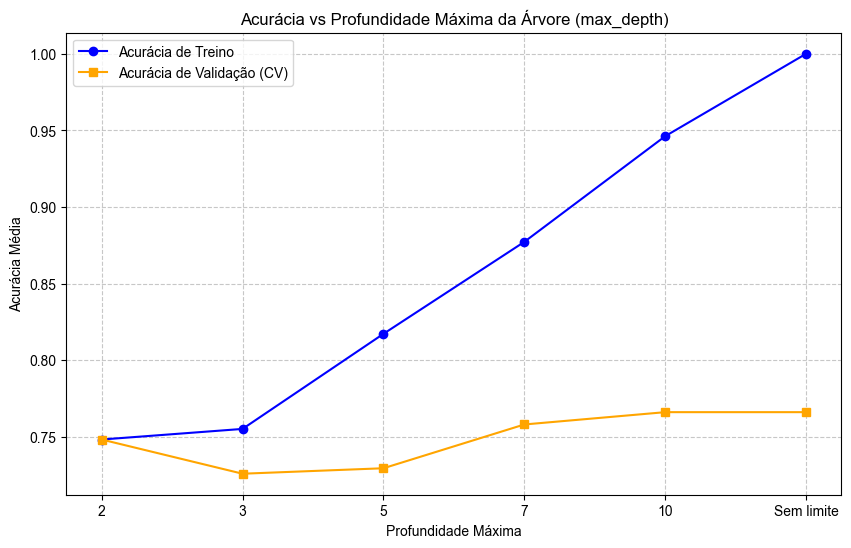

A melhor profundidade máxima encontrada foi: 10 com acurácia de validação de 0.7661


In [7]:
from sklearn.model_selection import cross_validate
import numpy as np
profundidades = [2, 3, 5, 7, 10, None]

train_scores = []
val_scores = []

for prof in profundidades:
    tree = DecisionTreeClassifier(criterion="gini", max_depth=prof, random_state=42)
    
    cv_results = cross_validate(tree, X_train_bal, y_train_bal, cv=5, return_train_score=True, scoring='accuracy')
    
    train_scores.append(np.mean(cv_results['train_score']))
    val_scores.append(np.mean(cv_results['test_score']))

labels_x = [str(p) if p is not None else 'Sem limite' for p in profundidades]

plt.figure(figsize=(10, 6))
plt.plot(labels_x, train_scores, marker='o', label='Acurácia de Treino', color='blue')
plt.plot(labels_x, val_scores, marker='s', label='Acurácia de Validação (CV)', color='orange')

plt.title('Acurácia vs Profundidade Máxima da Árvore (max_depth)')
plt.xlabel('Profundidade Máxima')
plt.ylabel('Acurácia Média')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

melhor_idx = np.argmax(val_scores)
melhor_profundidade = profundidades[melhor_idx]
print(f"A melhor profundidade máxima encontrada foi: {melhor_profundidade} com acurácia de validação de {val_scores[melhor_idx]:.4f}")

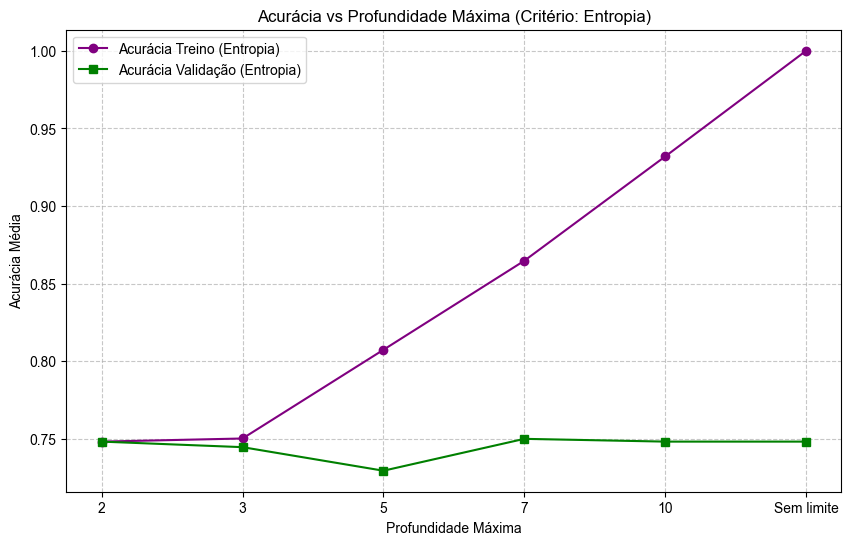

A melhor profundidade máxima com Entropia foi: 7 com acurácia de validação de 0.7500


In [8]:
train_scores_ent = []
val_scores_ent = []

for prof in profundidades:
    tree_ent = DecisionTreeClassifier(criterion='entropy', max_depth=prof, random_state=42)
    
    cv_results_ent = cross_validate(tree_ent, X_train_bal, y_train_bal, cv=5, return_train_score=True, scoring='accuracy')
    
    train_scores_ent.append(np.mean(cv_results_ent['train_score']))
    val_scores_ent.append(np.mean(cv_results_ent['test_score']))

labels_x = [str(p) if p is not None else 'Sem limite' for p in profundidades]

plt.figure(figsize=(10, 6))
plt.plot(labels_x, train_scores_ent, marker='o', label='Acurácia Treino (Entropia)', color='purple')
plt.plot(labels_x, val_scores_ent, marker='s', label='Acurácia Validação (Entropia)', color='green')

plt.title('Acurácia vs Profundidade Máxima (Critério: Entropia)')
plt.xlabel('Profundidade Máxima')
plt.ylabel('Acurácia Média')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

melhor_idx_ent = np.argmax(val_scores_ent)
print(f"A melhor profundidade máxima com Entropia foi: {profundidades[melhor_idx_ent]} com acurácia de validação de {val_scores_ent[melhor_idx_ent]:.4f}")

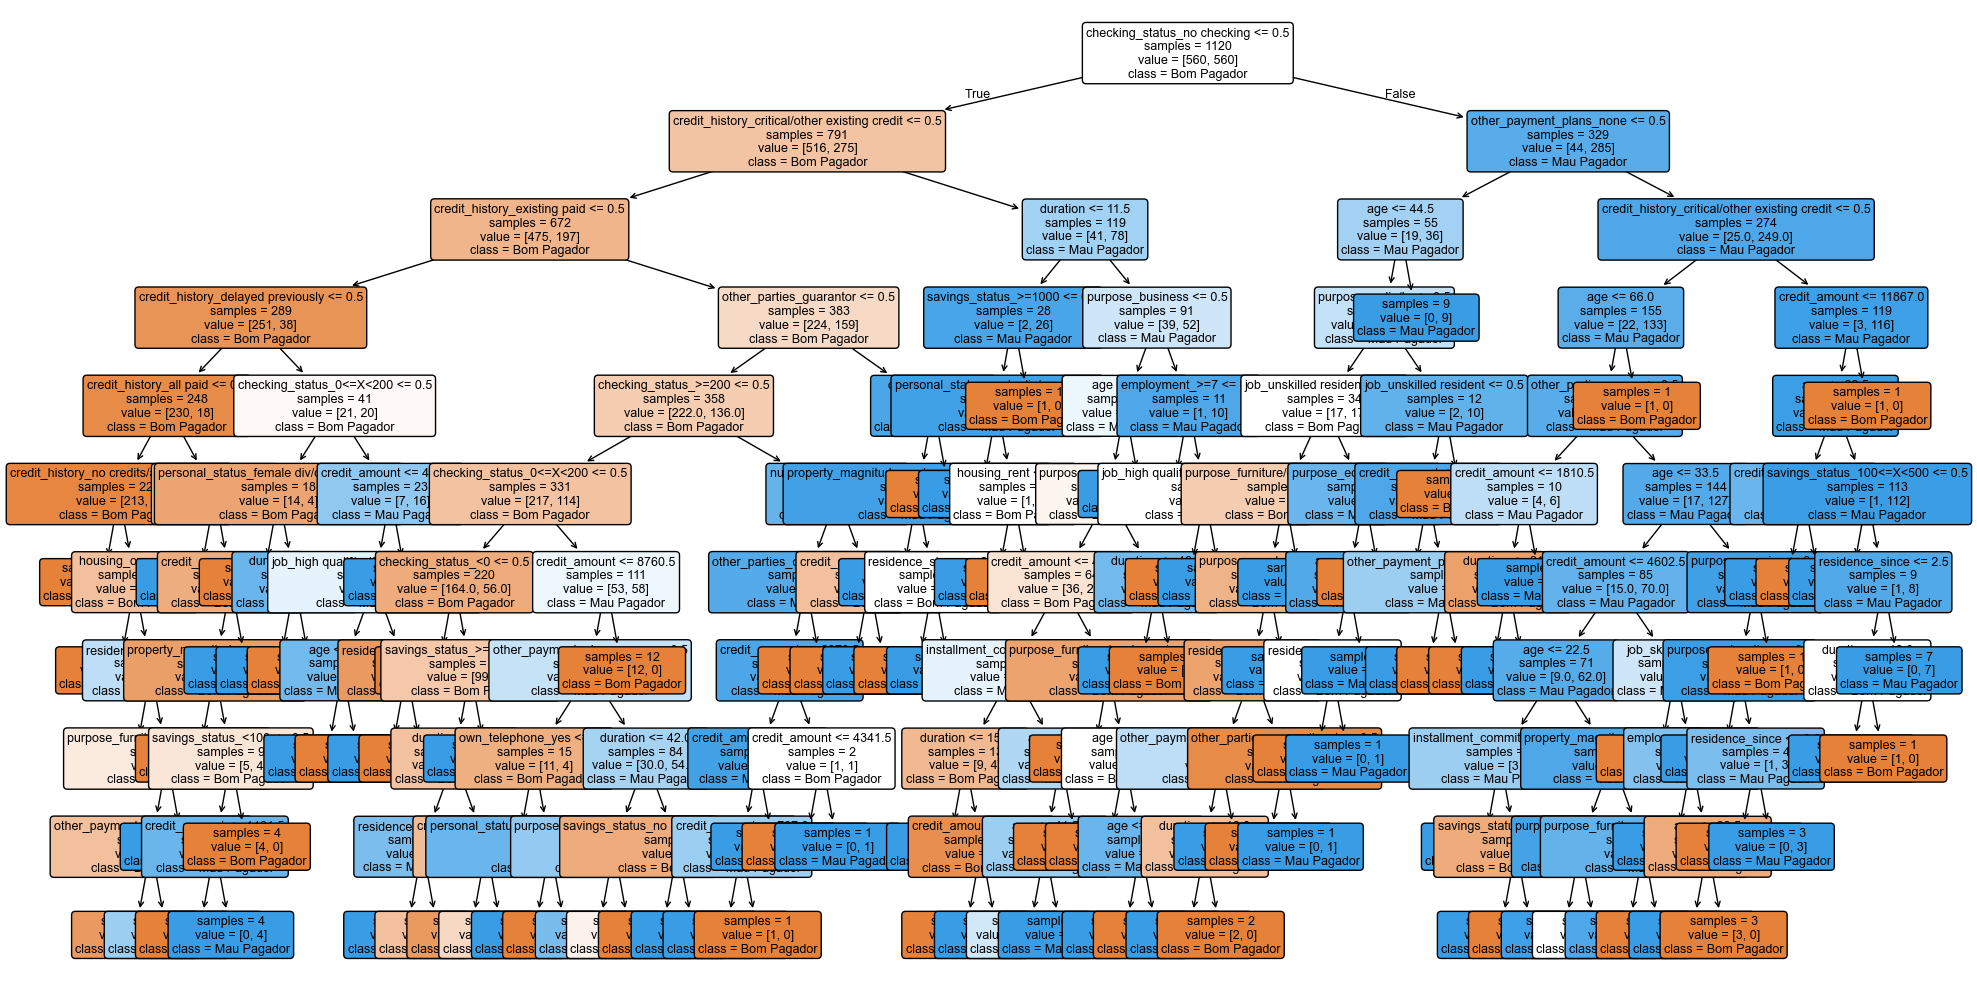

In [9]:
model = DecisionTreeClassifier(criterion="gini", max_depth=10, random_state=42)
model.fit(X_train_bal, y_train_bal)

nomes_features = X.columns.tolist()
nomes_classes = ["Bom Pagador", "Mau Pagador"] 

fig, ax = plt.subplots(figsize=(20, 10)) 
plot_tree(
        model,
        feature_names=nomes_features,
        class_names=nomes_classes,
        filled=True,
        impurity=False,
        rounded=True,
        fontsize=9,
        ax=ax
    )
fig.tight_layout()
plt.show()

In [12]:
y_prev = model.predict(X_test)

metricas = classification_report(y_test, y_prev)
print("\nMétricas por Classe:")
print(metricas)


Métricas por Classe:
              precision    recall  f1-score   support

         bad       0.50      0.52      0.51        60
        good       0.79      0.78      0.78       140

    accuracy                           0.70       200
   macro avg       0.64      0.65      0.65       200
weighted avg       0.70      0.70      0.70       200



In [13]:
print(confusion_matrix(y_prev, y_test))
print(f"Acurácia: {accuracy_score(y_test, y_prev):.4f}")

[[ 31  31]
 [ 29 109]]
Acurácia: 0.7000
